# Limpieza y transformación de datos: vehículos usados (Carroya)

## Objetivo
Dejar `carroya_dataset.csv` listo para entrenar tres modelos predictivos del proyecto: dos regresiones de `precio` (Gradient Boosting y Random Forest) y una clasificación del segmento de precio (BAJO / MEDIO / ALTO).

## Principios de este notebook
1. **Se conservan los registros.** Los valores imposibles pasan a faltantes (`NaN`) y se imputan después; solo se eliminan filas cuando el dato no se puede recuperar (precio imposible) o es un aviso repetido.
2. **Primero se divide, después se ajusta.** Imputadores, codificadores y escaladores se ajustan únicamente con entrenamiento, para evitar fuga de datos.
3. **Una sola fuente de verdad.** Las reglas de limpieza y el preprocesador viven en `Scripts/preprocesamiento.py`, el mismo módulo que usará el backend. Así se garantiza que los datos nuevos se transformen igual que en el entrenamiento.

## Entradas y salidas
- **Entrada:** `Scripts/data/carroya_dataset.csv` (resultado del scraper).
- **Salidas:** `Scripts/data/procesado/` (CSV limpio, particiones train/val/test, `cortes_segmento.json` y `carroya_auditoria_limpieza.csv` con cada corrección y su bandera) y `models/preprocesador.joblib`.

## Orden
1. Carga y auditoría · 2. Duplicados · 3. Selección de columnas · 4. Normalización de categorías · 5. Valores imposibles · 6. Precio objetivo · 7. Variables nuevas · 8. División 70/15/15 · 9. Variables objetivo · 10. Discretización, codificación y escalado (comparaciones) · 11. Preprocesador final · 12. Guardado y verificación de reproducibilidad.

> **Antes de ejecutar:** copia `preprocesamiento.py` en la carpeta `Scripts/` del proyecto (junto a `scraper_carroya.py`).

## 1. Carga y auditoría inicial
La ruta del CSV se resuelve buscando hacia arriba desde la carpeta actual, igual que en el notebook exploratorio, para poder ejecutarlo desde la raíz o desde `ETL/`. Además se agrega `Scripts/` a la ruta de importación para cargar el módulo compartido.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import KBinsDiscretizer, OneHotEncoder, RobustScaler, StandardScaler

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

project_root = Path.cwd()
while not (project_root / "Scripts" / "data" / "carroya_dataset.csv").is_file():
    if project_root == project_root.parent:
        raise FileNotFoundError("No se encontró Scripts/data/carroya_dataset.csv desde el directorio actual.")
    project_root = project_root.parent

sys.path.insert(0, str(project_root / "Scripts"))
import preprocesamiento as pp

SEMILLA = 42
csv_path = project_root / "Scripts" / "data" / "carroya_dataset.csv"
df = pd.read_csv(csv_path, encoding="utf-8-sig", low_memory=False)

# Registro de cuántas filas quedan después de cada decisión
registro = []
def anotar(etapa, filas):
    previo = registro[-1]["filas"] if registro else filas
    registro.append({"etapa": etapa, "filas": filas, "filas_removidas": previo - filas})

anotar("Datos originales", len(df))
print(f"Archivo: {csv_path}")
print(f"Dimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")

Archivo: c:\Users\diego\Documents\UNAL-26-2\Ciencia de Los Datos\Proyecto\YaCarroPredict-ProyectoCLD\Scripts\data\carroya_dataset.csv
Dimensiones: 20,494 filas x 34 columnas


In [2]:
auditoria = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores_unicos": df.nunique(dropna=True),
    "%_nulos": (df.isna().mean() * 100).round(2),
}).sort_values("%_nulos", ascending=False)
display(auditoria)

,tipo,valores_unicos,%_nulos
torque,str,1,94.95
tipo_direccion,str,1,94.95
unico_dueno,str,2,94.95
potencia,str,1,94.95
negociable,str,2,94.95
descripcion,str,15342,22.24
caracteristicas,str,1865,18.95
accesorios,str,9470,17.59
version,str,3404,5.08
transmision,str,3,0.75


## 2. Duplicados
Se revisan tres niveles:

- **Filas completas e `id` repetido:** el scraper ya deduplica por `id`; se confirma.
- **Mismo vehículo con distinto `id`:** un aviso republicado tendría igual marca, modelo, versión, año, kilometraje, precio, ciudad, color, combustible, transmisión y cilindraje. Si quedara una copia en entrenamiento y otra en prueba, las métricas saldrían infladas porque el modelo ya habría visto ese carro.
- **Excepción:** los avisos con kilometraje 0 (vehículos nuevos) se conservan, porque varias unidades idénticas del mismo concesionario son avisos legítimos distintos.

Cuando hay copias se conserva la **más reciente** según `fecha_publicacion`.

In [3]:
print(f"Filas duplicadas completas: {df.duplicated().sum():,}")
print(f"IDs duplicados:            {df['id'].duplicated().sum():,}")

claves = ["marca", "modelo", "version", "anio", "kilometraje", "precio",
          "ciudad", "color", "combustible", "transmision", "cilindraje"]
clave_df = df[claves].copy()
for col in ["marca", "modelo", "version", "ciudad", "color", "combustible", "transmision"]:
    clave_df[col] = pp.normalizar_texto(clave_df[col])

orden = pd.to_datetime(df["fecha_publicacion"], errors="coerce", utc=True).sort_values(ascending=False).index
df_ord = df.loc[orden]
repetido = clave_df.loc[orden].duplicated(keep="first") & df_ord["kilometraje"].gt(0)
print(f"Avisos repetidos del mismo vehículo (km > 0): {repetido.sum():,}")

display(df_ord.loc[repetido, ["id", "marca", "modelo", "anio", "kilometraje", "precio", "ciudad"]].head(8))

df = df_ord.loc[~repetido].sort_index().copy()
anotar("Se quitan avisos repetidos del mismo vehículo", len(df))

Filas duplicadas completas: 0
IDs duplicados:            0
Avisos repetidos del mismo vehículo (km > 0): 119


,id,marca,modelo,anio,kilometraje,precio,ciudad
5580,c3f4873f-670e-4bb2-8c72-609e2b6ba61c,Toyota,Prado,2017,160000,198900000,MEDELLIN
5645,2b355107-529e-45c8-846a-69fb0f1fef55,Nissan,Frontier,2020,167000,142000000,MEDELLIN
5729,ae3e78dc-9625-408c-bd8c-2dd3bfbeb8dd,Suzuki,Grand Vitara,2013,83000,49000000,BOGOTA
5780,b974b5e9-8562-4f1b-b82b-d29cac31f78e,Volkswagen,Gol Trendline,2019,47500,40900000,MEDELLIN
18,b2a158ff-ae7e-476f-98f6-8e85331f898b,Renault,Duster,2018,148000,51000000,ROLDANILLO
5857,c7255c2f-d0a9-4185-bb18-5eecb421e1b7,Nissan,Qashqai,2021,86000,90900000,CALI
1774,d2d2f273-9530-41ec-b254-ab2c891cefa7,Hyundai,Tucson,2015,172000,55800000,MEDELLIN
1921,29c935c9-b025-4461-a619-18d856aa5cea,Volkswagen,Gol,2015,100000,34900000,BOGOTA


## 3. Selección de columnas
Se conservan solo las variables que **un usuario conoce al cotizar un carro** (son las que pedirá el formulario del frontend) más el objetivo `precio`. El criterio para quitar cada una queda en la tabla. Las columnas constantes y las de más de 90 % de nulos se detectan automáticamente para dejar evidencia, y se descartan **las columnas, no las filas**.

In [4]:
MOTIVOS = {
    "fuente": "Constante: todos los avisos son de Carroya",
    "id": "Identificador, no es un predictor",
    "estado": "Casi constante: prácticamente todos los avisos son usados",
    "version": "Miles de categorías y nulos; lo esencial ya está en marca + modelo",
    "moneda": "Constante (PESO)",
    "color": "No se pide en el formulario y se descarta para limitar la cardinalidad",
    "ciudad": "Cientos de categorías; se usa departamento",
    "pico_placa": "Se deriva de la placa, no de las características del vehículo",
    "ciudad_placa": "Se deriva de la placa, no de las características del vehículo",
    "num_fotos": "Atributo del aviso, no disponible al cotizar",
    "fecha_publicacion": "Atributo del aviso; los datos son de un solo corte, no una serie de tiempo",
    "negociable": "Cerca de 95 % de nulos",
    "unico_dueno": "Cerca de 95 % de nulos",
    "blindado": "Rara y no se pide en el formulario (posible mejora futura)",
    "destacado": "Atributo de la plataforma, no del vehículo",
    "tipo_direccion": "Cerca de 95 % de nulos",
    "torque": "Cerca de 95 % de nulos",
    "potencia": "Cerca de 95 % de nulos",
    "titulo": "Texto libre; repite marca, modelo y año",
    "descripcion": "Texto libre; puede contener datos personales y exigiría NLP",
    "caracteristicas": "Texto libre; exigiría NLP",
    "accesorios": "Texto libre; exigiría NLP",
    "fecha_extraccion": "Constante en este corte",
}
CONSERVAR = pp.COLS_ENTRADA + ["precio"]

# Evidencia automática: constantes y muy nulas deben estar entre las descartadas
constantes = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]
muy_nulas = [c for c in df.columns if df[c].isna().mean() > 0.90]
assert set(constantes + muy_nulas) <= set(MOTIVOS), "Hay constantes o muy nulas sin decisión documentada"
assert set(CONSERVAR).isdisjoint(MOTIVOS), "Una columna conservada también está marcada para descartar"
faltan = set(df.columns) - set(CONSERVAR) - set(MOTIVOS)
assert not faltan, f"Columnas sin decisión: {faltan}"

print("Constantes detectadas:", constantes)
print("Más de 90 % de nulos:", muy_nulas)

decision = pd.DataFrame(
    [{"columna": c, "decision": "Se conserva", "motivo": "Variable de entrada del formulario" if c != "precio" else "Variable objetivo"} for c in CONSERVAR]
    + [{"columna": c, "decision": "Se descarta", "motivo": m} for c, m in MOTIVOS.items()]
)
display(decision)

df_raw = df.copy()          # copia completa, solo para consultar evidencia
df = df[CONSERVAR].copy()
print(f"\nColumnas conservadas: {df.shape[1]}")

Constantes detectadas: ['fuente', 'moneda', 'tipo_direccion', 'torque', 'potencia', 'fecha_extraccion']
Más de 90 % de nulos: ['negociable', 'unico_dueno', 'tipo_direccion', 'torque', 'potencia']


,columna,decision,motivo
0,marca,Se conserva,Variable de entrada del formulario
1,modelo,Se conserva,Variable de entrada del formulario
2,anio,Se conserva,Variable de entrada del formulario
3,kilometraje,Se conserva,Variable de entrada del formulario
4,combustible,Se conserva,Variable de entrada del formulario
5,transmision,Se conserva,Variable de entrada del formulario
6,cilindraje,Se conserva,Variable de entrada del formulario
7,carroceria,Se conserva,Variable de entrada del formulario
8,departamento,Se conserva,Variable de entrada del formulario
9,tipo_vendedor,Se conserva,Variable de entrada del formulario



Columnas conservadas: 11


## 4. Normalización de categorías
Se aplica una regla determinista a todo el texto categórico: quitar tildes, colapsar espacios y pasar a MAYÚSCULAS. Se eligió una regla fija (y no un mapa aprendido de los datos) porque el backend puede aplicarla igual a lo que escriba el usuario.

La tabla de abajo muestra cuántas categorías había antes y después, y las variantes que se fusionaron. **Revisa las fusiones**: la regla no puede saber, por ejemplo, si `MERCEDES-BENZ` y `MERCEDES BENZ` son lo mismo; esos casos se corrigen con un mapeo manual si aparecen.

In [5]:
def variantes_fusionadas(serie, top=6):
    original = serie.dropna().astype(str)
    clave = pp.normalizar_texto(original)
    grupos = pd.DataFrame({"original": original, "clave": clave}).groupby("clave")["original"].agg(lambda s: sorted(s.unique()))
    return grupos[grupos.map(len) > 1].head(top)

resumen_cat = []
for col in pp.COLS_TEXTO:
    antes = df[col].nunique(dropna=True)
    despues = pp.normalizar_texto(df[col]).nunique(dropna=True)
    resumen_cat.append({"columna": col, "categorias_antes": antes, "categorias_despues": despues})
display(pd.DataFrame(resumen_cat).set_index("columna"))

for col in ["departamento", "marca"]:
    print(f"\nVariantes fusionadas en {col}:")
    display(variantes_fusionadas(df[col]).to_frame("variantes"))

for col in pp.COLS_TEXTO:
    df[col] = pp.normalizar_texto(df[col])

,categorias_antes,categorias_despues
columna,,
marca,89,87
modelo,787,784
combustible,7,7
transmision,3,3
carroceria,6,6
departamento,58,38
tipo_vendedor,2,2



Variantes fusionadas en departamento:


,variantes
clave,
ANTIOQUIA,"[ANTIOQUIA, Antioquia]"
ATLANTICO,"[ATLANTICO, Atlántico]"
BOLIVAR,"[BOLIVAR, Bolivar]"
BOYACA,"[BOYACA, Boyacá]"
CALDAS,"[CALDAS, Caldas]"
CASANARE,"[CASANARE, Casanare]"



Variantes fusionadas en marca:


,variantes
clave,
CUPRA,"[CUPRA, Cupra]"
JETOUR,"[JETOUR, Jetour]"


## 5. Valores imposibles o dudosos
El análisis exploratorio mostró varios problemas numéricos. Regla general: **el registro se conserva y el valor dudoso pasa a `NaN`**; luego se imputa con la mediana de entrenamiento y se agrega un indicador de faltante.

| Variable | Regla | Razón |
|---|---|---|
| `anio` | Fuera de 1900 a (año de extracción + 1) → `NaN` | El año-modelo puede ir un año adelante, por eso 2027 se acepta |
| `kilometraje` | Negativo o mayor a 1.000.000 → `NaN` (incluye el relleno 9.999.999) | Valores imposibles o de relleno. Entre 500.000 y 1.000.000 se **conserva** (puede ser un taxi o un vehículo de trabajo real) y solo se reporta |
| `kilometraje` | 0 con año anterior a 2025 → `NaN` | Un usado de más de un año con 0 km no es creíble; en vehículos recientes sí lo es |
| `cilindraje` | Negativo → `NaN` | Imposible |
| `cilindraje` | Entero de 1 a 9 en no eléctricos → ×1000 | Se interpreta como litros (2 → 2.000 cc); ver evidencia abajo |
| `cilindraje` | 0 en no eléctricos, menor a 300 o mayor a 8.000 → `NaN` | Fuera de lo razonable para un automóvil. Parte de los mayores a 8.000 son una copia exacta del kilometraje (ver evidencia abajo) |
| `cilindraje` | Eléctricos → 0 | Un eléctrico no tiene cilindraje; 0 es un valor legítimo |

Los valores originales **no se pierden**: la celda de auditoría de más abajo guarda cada valor antes y después de la regla, con una bandera por regla, en un CSV aparte (no se usa como predictor). La conversión de litros es una **hipótesis** que se verifica con la celda siguiente. Si la evidencia no la respalda, cambia `CONVERTIR_LITROS` a `False` y esos valores pasan a `NaN` en su lugar.

In [6]:
# Evidencia para la hipótesis de litros: ¿qué dice la versión del aviso cuando cilindraje está entre 1 y 9?
pequenos = df.index[df["cilindraje"].between(1, pp.LITROS_MAX)]
print(f"Avisos con cilindraje entre 1 y {pp.LITROS_MAX}: {len(pequenos):,}")
display(df.loc[pequenos, "combustible"].value_counts().to_frame("avisos"))
display(df_raw.loc[pequenos, ["titulo", "version", "combustible", "cilindraje"]].head(10))

Avisos con cilindraje entre 1 y 9: 972


,avisos
combustible,
GASOLINA,857
DIESEL,66
HIBRIDO,43
GAS NATURAL,6


,titulo,version,combustible,cilindraje
232,Nissan Kicks 2026,Sense,Gasolina,2
299,Volkswagen T-Cross 2023,1.0 Confortline Automatica,Gasolina,1
324,KIA Carens 2017,2.0 LX Automatica,Gasolina,4
384,Chevrolet Tracker 2014,1.8 LS Mecanica,Gasolina,1
413,Toyota 4Runner 2007,Limited 4.0 Suv Automatica,Gasolina,6
426,Mazda 2 2025,Touring 1.5 Sedan Automatico,Gasolina,1
442,AUDI Q3 2021,NaN,Gasolina,1
451,Nissan March 2020,Advance Automatico,Gasolina,1
483,Nissan Murano 2018,3.5 4X4 AUT,Gasolina,6
484,Volkswagen Jetta 2007,2.0 Comfort Automatico,Gasolina,2


**Evidencia sobre los cilindrajes mayores a 8.000.** Si el scraper copió el kilometraje en la columna equivocada, esos valores serían idénticos al kilometraje del mismo aviso. La celda lo comprueba; los casos que coinciden son errores de extracción, no motores reales.

In [7]:
cc_alto = df["cilindraje"].gt(pp.CILINDRAJE_MAX)
cc_igual_km = cc_alto & df["cilindraje"].eq(df["kilometraje"])
print(f"Cilindraje mayor a {pp.CILINDRAJE_MAX:,}: {cc_alto.sum():,} avisos")
print(f"  de ellos, idénticos al kilometraje del mismo aviso: {cc_igual_km.sum():,}")
display(df_raw.loc[df.index[cc_igual_km], ["titulo", "kilometraje", "cilindraje"]].head(6))

km_intermedio = df["kilometraje"].between(500_000, pp.KM_MAX)
print(f"\nKilometraje entre 500.000 y {pp.KM_MAX:,} (se conserva): {km_intermedio.sum():,} avisos")
print(f"Kilometraje igual al relleno 9.999.999: {df['kilometraje'].eq(9_999_999).sum():,} avisos")

Cilindraje mayor a 8,000: 169 avisos
  de ellos, idénticos al kilometraje del mismo aviso: 35


,titulo,kilometraje,cilindraje
966,Nissan X-Trail 2020,53100,53100
1075,Ford Edge 2019,64000,64000
1380,Volkswagen Virtus 2022,16500,16500
2450,Chevrolet Tracker 2017,59000,59000
2954,Mini Cooper 2023,19500,19500
3098,Toyota Prado 2022,52000,52000



Kilometraje entre 500.000 y 1,000,000 (se conserva): 60 avisos
Kilometraje igual al relleno 9.999.999: 2 avisos


In [8]:
CONVERTIR_LITROS = True

antes = df[["anio", "kilometraje", "cilindraje"]].copy()
df = pp.sanear_numericos(df, convertir_litros=CONVERTIR_LITROS)
assert len(df) == len(antes), "El saneamiento no debe eliminar filas"

cambios = []
for col in ["anio", "kilometraje", "cilindraje"]:
    a_nan = (df[col].isna() & antes[col].notna()).sum()
    corregidos = ((df[col] != antes[col]) & df[col].notna() & antes[col].notna()).sum()
    cambios.append({"columna": col, "pasan_a_NaN": int(a_nan), "valores_corregidos": int(corregidos)})
display(pd.DataFrame(cambios).set_index("columna"))

display(pd.concat([antes.describe().add_suffix("_antes"), df[["anio", "kilometraje", "cilindraje"]].describe().add_suffix("_despues")], axis=1).T)

,pasan_a_NaN,valores_corregidos
columna,,
anio,0,0
kilometraje,27,0
cilindraje,2437,982


,count,mean,std,min,25%,50%,75%,max
anio_antes,"20,375.00","2,016.17",7.72,"1,946.00","2,013.00","2,017.00","2,021.00","2,027.00"
kilometraje_antes,"20,375.00","93,124.47","145,210.85",0.00,"42,100.00","78,000.00","120,079.50","9,999,999.00"
cilindraje_antes,"20,375.00","1,783.43","2,916.16","-1,800.00","1,248.00","1,600.00","2,000.00","99,000.00"
anio_despues,"20,375.00","2,016.17",7.72,"1,946.00","2,013.00","2,017.00","2,021.00","2,027.00"
kilometraje_despues,"20,348.00","90,099.69","72,246.17",0.00,"42,000.00","77,800.00","120,000.00","1,000,000.00"
cilindraje_despues,"17,938.00","1,896.07",740.17,0.00,"1,500.00","1,600.00","2,000.00","8,000.00"


### Auditoría de las correcciones
Para poder justificar cada cambio ante el docente (o revertirlo), se arma una tabla con el valor original, el valor final y una bandera por regla. Estas banderas son **de auditoría**: no entran al modelo.

In [9]:
auditoria = pd.DataFrame({"id": df_raw.loc[df.index, "id"]})
auditoria["kilometraje_original"] = antes["kilometraje"]
auditoria["kilometraje_final"] = df["kilometraje"]
auditoria["cilindraje_original"] = antes["cilindraje"]
auditoria["cilindraje_final"] = df["cilindraje"]
auditoria["flag_km_a_nan"] = df["kilometraje"].isna() & antes["kilometraje"].notna()
auditoria["flag_km_relleno"] = antes["kilometraje"].eq(9_999_999)
auditoria["flag_km_extremo_conservado"] = antes["kilometraje"].between(500_000, pp.KM_MAX) & df["kilometraje"].notna()
auditoria["flag_cilindraje_a_nan"] = df["cilindraje"].isna() & antes["cilindraje"].notna()
auditoria["flag_cilindraje_litros"] = df["cilindraje"].notna() & (df["cilindraje"] != antes["cilindraje"]) & antes["cilindraje"].between(1, pp.LITROS_MAX)
auditoria["flag_cilindraje_igual_km"] = antes["cilindraje"].gt(pp.CILINDRAJE_MAX) & antes["cilindraje"].eq(antes["kilometraje"])
auditoria["flag_anio_posterior_extraccion"] = antes["anio"].gt(pp.ANIO_REFERENCIA)

banderas = [c for c in auditoria.columns if c.startswith("flag_")]
display(auditoria[banderas].sum().astype(int).to_frame("registros"))
auditoria_marcada = auditoria.loc[auditoria[banderas].any(axis=1)]
print(f"Registros con al menos una bandera: {len(auditoria_marcada):,}")

,registros
flag_km_a_nan,27
flag_km_relleno,2
flag_km_extremo_conservado,60
flag_cilindraje_a_nan,2437
flag_cilindraje_litros,972
flag_cilindraje_igual_km,35
flag_anio_posterior_extraccion,53


Registros con al menos una bandera: 3,513


## 6. Precio objetivo
El precio es el objetivo; un precio imposible **no se puede imputar** sin inventar la respuesta, así que estos son los únicos registros que se eliminan por valor. Se usa un umbral mínimo (`PRECIO_MIN`, 3 millones de pesos). Los precios muy altos **no se eliminan**: pueden ser vehículos genuinos (deportivos, camionetas de lujo), y se revisan abajo.

Avisos con precio faltante o menor a 3,000,000: 2


,titulo,anio,kilometraje,precio
3098,Toyota Prado 2022,2022,52000,308000
10643,Mazda 626 1989,1989,278000,2500000



Los 10 precios más altos (se conservan; revisa que sean coherentes):


,marca,modelo,anio,kilometraje,precio
6155,MERCEDES BENZ,CLASE G,2021,"72,700.00",1200000000
8438,PORSCHE,911,2026,101.00,999000000
12939,PORSCHE,911,2018,"28,000.00",987000000
11862,CADILLAC,ESCALADE,2025,"10,769.00",986000000
9269,PORSCHE,911,2026,101.00,790000000
11500,TOYOTA,LAND CRUISER,2024,"6,997.00",770000000
7278,CHEVROLET,CORVETTE,2026,100.00,749000000
5442,TOYOTA,LAND CRUISER,2025,100.00,729990000
13898,TOYOTA,LAND CRUISER,2024,"7,700.00",729900000
6048,TOYOTA,LAND CRUISER,2025,"6,800.00",699000000


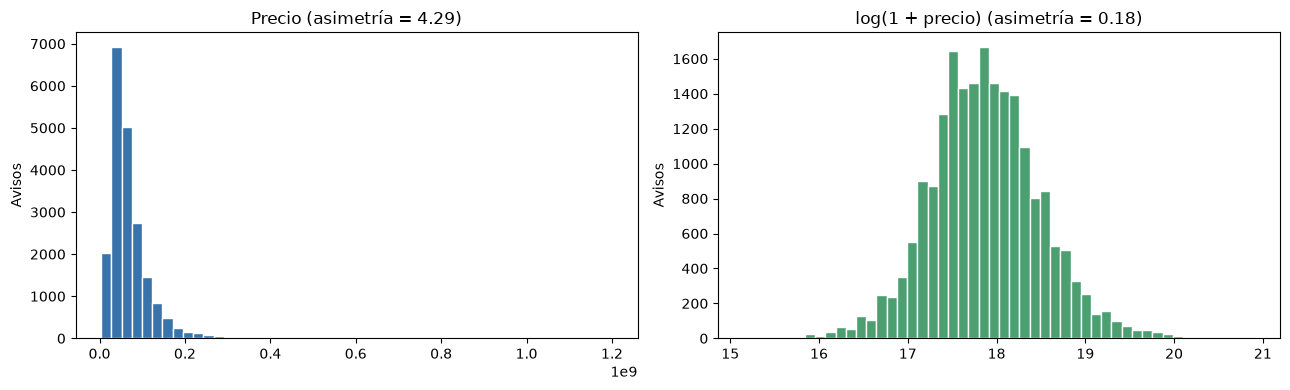

In [10]:
bajo = df["precio"].isna() | (df["precio"] < pp.PRECIO_MIN)
print(f"Avisos con precio faltante o menor a {pp.PRECIO_MIN:,}: {bajo.sum():,}")
display(df_raw.loc[df.index[bajo], ["titulo", "anio", "kilometraje", "precio"]].head(8))

df = df.loc[~bajo].copy()
anotar("Se quitan precios imposibles", len(df))

print("\nLos 10 precios más altos (se conservan; revisa que sean coherentes):")
display(df.nlargest(10, "precio")[["marca", "modelo", "anio", "kilometraje", "precio"]])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(df["precio"], bins=50, color="#3973ac", edgecolor="white")
ax[0].set_title(f"Precio (asimetría = {df['precio'].skew():.2f})")
ax[1].hist(np.log1p(df["precio"]), bins=50, color="#4c9f70", edgecolor="white")
ax[1].set_title(f"log(1 + precio) (asimetría = {np.log1p(df['precio']).skew():.2f})")
for a in ax:
    a.set_ylabel("Avisos")
fig.tight_layout()
plt.show()

**Decisión:** los modelos de regresión se entrenan sobre `log(1 + precio)`. La distribución original está muy sesgada a la derecha y el error relativo importa más que el absoluto (equivocarse por 5 millones pesa distinto en un carro de 20 millones que en uno de 300). Las métricas finales (MAE, RMSE, MAPE) se reportan **en pesos**, revirtiendo la transformación con `pp.a_pesos`.

## 7. Variables nuevas
`crear_variables` (del módulo compartido) normaliza el texto, sanea los numéricos y crea:

- `antiguedad = 2026 − anio` (mínimo 0). Resume el año en un valor más interpretable y evita la colinealidad con `anio`, que se descarta.
- `km_por_anio = kilometraje / antiguedad` (con antigüedad mínima 1). Distingue un carro de uso intensivo de uno de poco uso.
- `marca_modelo`: el nombre del modelo solo puede repetirse entre marcas; combinado evita colisiones.

El resultado trae exactamente las columnas que entran al modelo (`COLS_MODELO`).

Columnas del modelo (11): ['kilometraje', 'km_por_anio', 'antiguedad', 'cilindraje', 'combustible', 'transmision', 'carroceria', 'tipo_vendedor', 'marca', 'marca_modelo', 'departamento']



,tipo,%_nulos,valores_unicos
kilometraje,float64,0.13,4772
km_por_anio,float64,0.13,7090
antiguedad,int64,0.00,77
cilindraje,float64,11.96,412
combustible,str,0.00,7
transmision,str,0.75,3
carroceria,str,0.00,6
tipo_vendedor,str,0.00,2
marca,str,0.00,87
marca_modelo,str,0.00,806


,count,mean,std,min,25%,50%,75%,max
kilometraje,"20,346.00","90,092.33","72,237.22",0.00,"42,000.00","77,800.00","120,000.00","1,000,000.00"
km_por_anio,"20,346.00","10,375.48","7,101.06",0.00,"6,873.56","9,333.33","12,444.44","333,333.33"
antiguedad,"20,373.00",9.83,7.72,0.00,5.00,9.00,13.00,80.00
cilindraje,"17,937.00","1,896.08",740.19,0.00,"1,500.00","1,600.00","2,000.00","8,000.00"


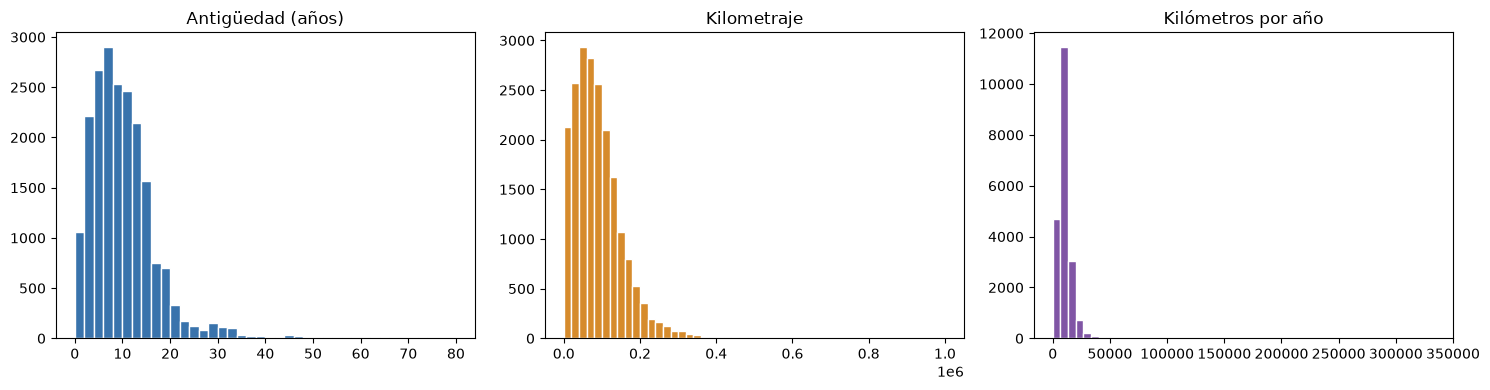

,kilometraje,km_por_anio,antiguedad,cilindraje,log_precio
kilometraje,1.00,0.40,0.74,0.18,-0.56
km_por_anio,0.40,1.00,-0.20,-0.05,0.06
antiguedad,0.74,-0.20,1.00,0.23,-0.69
cilindraje,0.18,-0.05,0.23,1.00,0.27
log_precio,-0.56,0.06,-0.69,0.27,1.00


In [11]:
X_todo = pp.crear_variables(df[pp.COLS_ENTRADA])
print(f"Columnas del modelo ({len(pp.COLS_MODELO)}): {pp.COLS_MODELO}\n")

display(pd.DataFrame({
    "tipo": X_todo.dtypes.astype(str),
    "%_nulos": (X_todo.isna().mean() * 100).round(2),
    "valores_unicos": X_todo.nunique(),
}))
display(X_todo[pp.NUM_SESGADAS + pp.NUM_SIMPLES].describe().T)

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(X_todo["antiguedad"].dropna(), bins=40, color="#3973ac", edgecolor="white"); ax[0].set_title("Antigüedad (años)")
ax[1].hist(X_todo["kilometraje"].dropna(), bins=50, color="#d68b2c", edgecolor="white"); ax[1].set_title("Kilometraje")
ax[2].hist(X_todo["km_por_anio"].dropna(), bins=50, color="#8055a5", edgecolor="white"); ax[2].set_title("Kilómetros por año")
fig.tight_layout()
plt.show()

corr = pd.concat([X_todo[pp.NUM_SESGADAS + pp.NUM_SIMPLES], np.log1p(df["precio"]).rename("log_precio")], axis=1).corr(method="spearman")
display(corr.round(3))

## 8. División 70 / 15 / 15
Los datos son un corte único del mercado, **no una serie de tiempo**, así que la división es aleatoria. Se estratifica por deciles de precio para que las tres particiones tengan una distribución de precio parecida. A partir de aquí **todo lo que aprende de los datos se ajusta solo con entrenamiento**.

In [12]:
estrato = pd.qcut(df["precio"], q=10, labels=False, duplicates="drop")
idx_train, idx_tmp = train_test_split(df.index, test_size=0.30, random_state=SEMILLA, stratify=estrato)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, random_state=SEMILLA, stratify=estrato.loc[idx_tmp])

train, val, test = df.loc[idx_train].copy(), df.loc[idx_val].copy(), df.loc[idx_test].copy()
display(pd.DataFrame({
    "filas": [len(train), len(val), len(test)],
    "%": [round(100 * len(p) / len(df), 1) for p in (train, val, test)],
    "precio_mediano": [p["precio"].median() for p in (train, val, test)],
    "precio_promedio": [p["precio"].mean() for p in (train, val, test)],
}, index=["train", "val", "test"]))

,filas,%,precio_mediano,precio_promedio
train,14261,70.00,"56,900,000.00","70,686,003.54"
val,3056,15.00,"56,600,000.00","71,227,154.95"
test,3056,15.00,"56,900,000.00","71,302,674.87"


## 9. Variables objetivo
- **Regresión:** `log(1 + precio)`, que se calcula al entrenar.
- **Clasificación:** `segmento_precio` con tres clases (BAJO / MEDIO / ALTO) definidas por los **terciles del precio en entrenamiento**. Los mismos cortes se aplican a validación y prueba (si se calcularan con todos los datos, la prueba influiría en la definición de las clases). Es una discretización por igual frecuencia, que produce clases balanceadas por construcción.

In [13]:
cortes = train["precio"].quantile([1 / 3, 2 / 3]).tolist()
print(f"Cortes de segmento (terciles de train): BAJO <= {cortes[0]:,.0f} < MEDIO <= {cortes[1]:,.0f} < ALTO")

for particion in (train, val, test):
    particion["segmento_precio"] = pp.asignar_segmento(particion["precio"], cortes)

display(pd.DataFrame({
    nombre: p["segmento_precio"].value_counts(normalize=True).reindex(pp.ETIQUETAS_SEGMENTO).mul(100).round(1)
    for nombre, p in (("train", train), ("val", val), ("test", test))
}).rename_axis("segmento (%)"))

Cortes de segmento (terciles de train): BAJO <= 43,333,333 < MEDIO <= 73,000,000 < ALTO


,train,val,test
segmento (%),,,
BAJO,33.30,32.90,33.50
MEDIO,33.50,33.90,33.10
ALTO,33.20,33.30,33.30


## 10. Discretización, codificación y escalado: comparaciones
Estas celdas replican el análisis comparativo de los notebooks de ejemplo (Titanic), pero **usando solo entrenamiento**. Cada comparación termina en una decisión.

### 10.1 Discretización de `antiguedad`
Se comparan tres estrategias (igual ancho, igual frecuencia y k-means) con 5 intervalos, midiendo cuánta información del precio se pierde al discretizar.

In [14]:
X_train_vars = pp.crear_variables(train[pp.COLS_ENTRADA])
ant = X_train_vars[["antiguedad"]].dropna()
precio_train = train.loc[ant.index, "precio"]

filas, tablas = [], {}
for estrategia in ["uniform", "quantile", "kmeans"]:
    disc = KBinsDiscretizer(n_bins=5, encode="ordinal", strategy=estrategia)
    grupos = pd.Series(disc.fit_transform(ant).ravel().astype(int), index=ant.index)
    tablas[estrategia] = pd.DataFrame({
        "limite_inferior": disc.bin_edges_[0][:-1].round(1),
        "limite_superior": disc.bin_edges_[0][1:].round(1),
        "avisos": grupos.value_counts().sort_index().values,
        "precio_mediano": precio_train.groupby(grupos).median().values,
    })
    filas.append({"estrategia": estrategia, "spearman_con_precio": grupos.corr(precio_train, method="spearman")})

filas.append({"estrategia": "continua (sin discretizar)", "spearman_con_precio": ant["antiguedad"].corr(precio_train, method="spearman")})
display(pd.DataFrame(filas).set_index("estrategia"))
for estrategia, tabla in tablas.items():
    print(f"\n{estrategia}:")
    display(tabla)

,spearman_con_precio
estrategia,
uniform,-0.44
quantile,-0.68
kmeans,-0.64
continua (sin discretizar),-0.69



uniform:


,limite_inferior,limite_superior,avisos,precio_mediano
0,0.00,16.00,12281,"62,000,000.00"
1,16.00,32.00,1721,"27,000,000.00"
2,32.00,48.00,179,"22,000,000.00"
3,48.00,64.00,51,"39,000,000.00"
4,64.00,80.00,29,"28,000,000.00"



quantile:


,limite_inferior,limite_superior,avisos,precio_mediano
0,0.00,4.00,2279,"93,000,000.00"
1,4.00,7.00,2868,"76,500,000.00"
2,7.00,10.00,2799,"60,100,000.00"
3,10.00,14.00,3220,"43,000,000.00"
4,14.00,80.00,3095,"30,000,000.00"



kmeans:


,limite_inferior,limite_superior,avisos,precio_mediano
0,0.00,9.20,7946,"75,000,000.00"
1,9.20,19.20,5375,"39,500,000.00"
2,19.20,34.20,762,"20,750,000.00"
3,34.20,54.10,122,"26,000,000.00"
4,54.10,80.00,56,"30,000,000.00"


**Decisión: no se discretiza `antiguedad` en el pipeline.** Los árboles (Random Forest, Gradient Boosting) encuentran sus propios puntos de corte, y la variable continua conserva al menos tanta relación con el precio como cualquier versión discretizada (compara el valor absoluto de la correlación de Spearman en la tabla). La discretización solo se usa para definir las clases del `segmento_precio`.

### 10.2 Codificación de categóricas
Se compara el número de columnas que genera cada categórica con One-Hot completo y con One-Hot que agrupa las categorías raras (`min_frecuencia`).

In [15]:
cat_cols = pp.CAT_BAJA + pp.CAT_ALTA
filas = []
for col in cat_cols:
    serie = X_train_vars[[col]].fillna("NO INFORMADO")
    completo = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(serie)
    agrupado = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=pp.MIN_FRECUENCIA, sparse_output=False).fit(serie)
    raras = agrupado.infrequent_categories_[0]
    cobertura_raras = serie[col].isin(raras).mean() * 100 if raras is not None else 0.0
    filas.append({
        "columna": col,
        "categorias": len(completo.categories_[0]),
        "cols_onehot_completo": len(completo.get_feature_names_out()),
        "cols_onehot_agrupado": len(agrupado.get_feature_names_out()),
        "%_avisos_en_raras": round(cobertura_raras, 2),
    })
display(pd.DataFrame(filas).set_index("columna"))

,categorias,cols_onehot_completo,cols_onehot_agrupado,%_avisos_en_raras
columna,,,,
combustible,7,7,6,0.31
transmision,4,4,4,0.00
carroceria,6,6,5,0.18
tipo_vendedor,2,2,2,0.00
marca,83,83,33,1.75
marca_modelo,741,741,109,26.32
departamento,35,35,23,0.49


**Decisión: One-Hot con `min_frecuencia = 30` para todas las categóricas.**

- **Label/Ordinal:** se descarta; impone un orden falso entre marcas o departamentos.
- **Frecuencia:** se descarta; dos marcas con la misma frecuencia quedarían iguales.
- **Target Encoding:** se descarta como opción principal; aprende del precio y exige validación cruzada interna para no filtrar información.
- **One-Hot agrupado:** conserva la identidad de cada categoría frecuente y reduce el ruido de las raras (`marca_modelo` tiene cientos de categorías). En validación y prueba, una categoría que no se vio en entrenamiento cae en el grupo de raras sin romper el backend (`handle_unknown="infrequent_if_exist"`).

### 10.3 Escalado
`kilometraje` y `km_por_anio` tienen colas muy largas. Se compara el efecto de los extremos con el escalado estándar (media y desviación) frente al robusto (mediana y rango intercuartílico), y el sesgo antes y después de `log1p`.

In [16]:
comparacion = []
for col in pp.NUM_SESGADAS:
    x = X_train_vars[[col]].dropna()
    z_estandar = StandardScaler().fit_transform(x).max()
    z_robusto = RobustScaler().fit_transform(x).max()
    x_log = np.log1p(x)
    comparacion.append({
        "variable": col,
        "asimetria_original": x[col].skew(),
        "asimetria_log1p": x_log[col].skew(),
        "maximo_escalado_estandar": z_estandar,
        "maximo_escalado_robusto": z_robusto,
        "maximo_robusto_tras_log": RobustScaler().fit_transform(x_log).max(),
        "log1p_reduce_sesgo": bool(abs(x_log[col].skew()) < abs(x[col].skew())),
    })
tabla_escalado = pd.DataFrame(comparacion).set_index("variable")
display(tabla_escalado)
if not tabla_escalado["log1p_reduce_sesgo"].all():
    print("ATENCIÓN: log1p no reduce el sesgo en alguna variable; considera USAR_LOG_NUMERICAS = False en preprocesamiento.py")

,asimetria_original,asimetria_log1p,maximo_escalado_estandar,maximo_escalado_robusto,maximo_robusto_tras_log,log1p_reduce_sesgo
variable,,,,,,
kilometraje,2.91,-2.84,12.73,11.86,2.45,True
km_por_anio,5.12,-4.32,26.75,32.84,5.09,True


**Decisión (condicionada a la tabla):** para `kilometraje` y `km_por_anio` se aplica `log1p` y luego `RobustScaler`, siempre que la columna `log1p_reduce_sesgo` sea `True` en ambas. Si alguna da `False` (puede pasar cuando hay muchos vehículos casi nuevos con kilometraje cercano a 0, que el log estira hacia la izquierda), cambia `USAR_LOG_NUMERICAS` a `False` en `preprocesamiento.py` y vuelve a ejecutar el notebook; el `RobustScaler` solo ya controla el efecto de los extremos. `antiguedad` y `cilindraje` solo llevan `RobustScaler`. Los árboles no necesitan escalado, pero la Regresión Logística (si se usa en el modelo de clasificación) sí, y el mismo preprocesador sirve a los tres modelos.

## 11. Preprocesador final
El preprocesador completo (variables derivadas + imputación + indicadores de faltante + log + escalado + One-Hot) es un `Pipeline` de scikit-learn. Se **ajusta con entrenamiento** y se aplica a validación y prueba.

In [17]:
preprocesador = pp.construir_pipeline_preprocesamiento()
X_train_t = preprocesador.fit_transform(train[pp.COLS_ENTRADA])
X_val_t = preprocesador.transform(val[pp.COLS_ENTRADA])
X_test_t = preprocesador.transform(test[pp.COLS_ENTRADA])

nombres = preprocesador.named_steps["transformador"].get_feature_names_out()
print(f"Matriz train: {X_train_t.shape} | val: {X_val_t.shape} | test: {X_test_t.shape}")
print(f"Valores faltantes tras transformar: train={np.isnan(X_train_t).sum()}, val={np.isnan(X_val_t).sum()}, test={np.isnan(X_test_t).sum()}")

grupos_cols = pd.Series([n.split("__")[0] for n in nombres]).value_counts().rename("columnas")
display(grupos_cols.to_frame())
display(pd.DataFrame(X_train_t[:, :6], columns=nombres[:6]).describe().T)

Matriz train: (14261, 188) | val: (3056, 188) | test: (3056, 188)
Valores faltantes tras transformar: train=0, val=0, test=0


,columnas
categoricas,182
faltante,2
num_sesgadas,2
num_simples,2


,count,mean,std,min,25%,50%,75%,max
faltante__missingindicator_kilometraje,"14,261.00",0.00,0.04,0.00,0.00,0.00,0.00,1.00
faltante__missingindicator_cilindraje,"14,261.00",0.12,0.33,0.00,0.00,0.00,0.00,1.00
num_sesgadas__kilometraje,"14,261.00",-0.24,1.15,-10.85,-0.58,0.00,0.42,2.46
num_sesgadas__km_por_anio,"14,261.00",-0.23,1.66,-15.39,-0.52,0.00,0.48,5.10
num_simples__antiguedad,"14,261.00",0.10,0.95,-1.12,-0.50,0.00,0.50,8.88
num_simples__cilindraje,"14,261.00",0.24,1.73,-4.47,-0.49,0.00,0.51,15.43


## 12. Guardado y verificación de reproducibilidad
Se guardan: el CSV limpio, las tres particiones, los cortes del segmento y el preprocesador ajustado. Después se **recarga** el preprocesador y se comprueba que da exactamente el mismo resultado, incluso con entradas escritas "a mano" como las del formulario (sin normalizar).

El notebook de entrenamiento construirá un `Pipeline` por modelo (este preprocesamiento + el algoritmo) y lo guardará con `joblib`; el backend cargará esos archivos una sola vez al iniciar.

In [18]:
carpeta_datos = project_root / "Scripts" / "data" / "procesado"
carpeta_modelos = project_root / "models"
carpeta_datos.mkdir(parents=True, exist_ok=True)
carpeta_modelos.mkdir(parents=True, exist_ok=True)

columnas_guardar = pp.COLS_ENTRADA + ["precio", "segmento_precio"]
for nombre, particion in (("train", train), ("val", val), ("test", test)):
    particion[columnas_guardar].to_csv(carpeta_datos / f"carroya_{nombre}.csv", index=False, encoding="utf-8-sig")
pd.concat([train, val, test])[columnas_guardar].sort_index().to_csv(carpeta_datos / "carroya_limpio.csv", index=False, encoding="utf-8-sig")

auditoria_marcada.to_csv(carpeta_datos / "carroya_auditoria_limpieza.csv", index=False, encoding="utf-8-sig")

with open(carpeta_datos / "cortes_segmento.json", "w", encoding="utf-8") as f:
    json.dump({"cortes": cortes, "etiquetas": pp.ETIQUETAS_SEGMENTO}, f, indent=2)

joblib.dump(preprocesador, carpeta_modelos / "preprocesador.joblib")
print("Guardado en:", carpeta_datos)
print("Preprocesador en:", carpeta_modelos / "preprocesador.joblib")

Guardado en: c:\Users\diego\Documents\UNAL-26-2\Ciencia de Los Datos\Proyecto\YaCarroPredict-ProyectoCLD\Scripts\data\procesado
Preprocesador en: c:\Users\diego\Documents\UNAL-26-2\Ciencia de Los Datos\Proyecto\YaCarroPredict-ProyectoCLD\models\preprocesador.joblib


In [19]:
# 0) Controles de integridad: no se perdieron ni se duplicaron registros entre particiones
assert len(train) + len(val) + len(test) == len(df)
assert not (set(train.index) & set(val.index)) and not (set(train.index) & set(test.index)) and not (set(val.index) & set(test.index))
assert df.index.is_unique
print("OK: las tres particiones suman todos los registros y no se solapan.")

# 1) Recargar y comparar con el original
cargado = joblib.load(carpeta_modelos / "preprocesador.joblib")
muestra = test[pp.COLS_ENTRADA].head(200)
assert np.allclose(cargado.transform(muestra), preprocesador.transform(muestra)), "El preprocesador recargado no coincide"
print("OK: el preprocesador recargado produce la misma matriz.")

# 2) Entrada como la escribiría un usuario en el formulario (sin normalizar)
ejemplo = pd.DataFrame([{
    "marca": "chevrolet", "modelo": "Tracker", "anio": 2020, "kilometraje": 60000,
    "combustible": "Gasolina", "transmision": "Automática", "cilindraje": 1200,
    "carroceria": "Camionetas", "departamento": "Antioquia", "tipo_vendedor": "Particular",
}])
salida = cargado.transform(ejemplo)
print(f"OK: una entrada cruda del formulario produce una fila de {salida.shape[1]} columnas, sin faltantes: {not np.isnan(salida).any()}")

# 3) Revertir el log a pesos (se usará con las predicciones de regresión)
print(f"Ejemplo de reversión: log1p(50.000.000) = {np.log1p(50_000_000):.4f} -> {pp.a_pesos(np.log1p(50_000_000)):,.0f} COP")

OK: las tres particiones suman todos los registros y no se solapan.
OK: el preprocesador recargado produce la misma matriz.
OK: una entrada cruda del formulario produce una fila de 188 columnas, sin faltantes: True
Ejemplo de reversión: log1p(50.000.000) = 17.7275 -> 50,000,000 COP


## Resumen del proceso
La tabla muestra cuántas filas quedaron después de cada decisión que elimina registros.

In [20]:
anotar("Datos para modelar (train + val + test)", len(train) + len(val) + len(test))
display(pd.DataFrame(registro).set_index("etapa"))

,filas,filas_removidas
etapa,,
Datos originales,20494,0
Se quitan avisos repetidos del mismo vehículo,20375,119
Se quitan precios imposibles,20373,2
Datos para modelar (train + val + test),20373,0


## Parámetros que conviene revisar tras ejecutar
Todas las reglas dependen de umbrales definidos en `preprocesamiento.py`. Después de ejecutar, revisa las tablas de cada sección y ajusta si algo no tiene sentido con tus datos reales:

- `KM_MAX` (1.000.000), `CILINDRAJE_MIN`, `CILINDRAJE_MAX`, `PRECIO_MIN`: ¿cuántos registros afecta cada uno (tablas de las secciones 5 y 6 y auditoría)? Si ves que entre 500.000 y 1.000.000 hay muchos errores evidentes, baja `KM_MAX`.
- `CONVERTIR_LITROS`: ¿la evidencia de la sección 5 respalda la conversión?
- Fusiones de categorías (sección 4): ¿hay variantes que la regla no unió o que unió mal?
- `MIN_FRECUENCIA`: si el porcentaje de avisos en categorías raras (sección 10.2) es alto, bájalo.

Si cambias algún parámetro, **vuelve a ejecutar todo el notebook** para regenerar el preprocesador y las particiones.